# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary. 

Used Car Dealership wanted to know which features of the vehicle such as year, manufacturer, model, condition, cylinders, fuel, odometer, title_status, transmission, drive, size, type, paint_color, state etc. contribute the car price the most and the least. The data set contains all these features and the appropriate model will be created and visualized to identify the most influential features. The final report will be provided to the Used Car Dealership.

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

First step is to get to understand the data. For this, first load the dataset into the dataframe. Review the dataframe structure with the total rows and each column's missing values, etc.

In [52]:
# Install the Libraries
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [56]:
# Import the Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge, LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn import set_config
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.inspection import permutation_importance
#from ydata_profiling import ProfileReport
#from category_encoders import TargetEncoder
from sklearn.feature_selection import SequentialFeatureSelector

In [57]:
vehicle_original_df = pd.read_csv("data/vehicles.csv") # Load the dataset
vehicle_original_df.info() # Display information about the dataset
vehicle_original_df.head() # Display the first few rows of the dataset

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  str    
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  str    
 5   model         421603 non-null  str    
 6   condition     252776 non-null  str    
 7   cylinders     249202 non-null  str    
 8   fuel          423867 non-null  str    
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  str    
 11  transmission  424324 non-null  str    
 12  VIN           265838 non-null  str    
 13  drive         296313 non-null  str    
 14  size          120519 non-null  str    
 15  type          334022 non-null  str    
 16  paint_color   296677 non-null  str    
 17  state         426880 non-null  str    
dtypes: float64(2), 

,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


Original Data Set:
There are total 426,880 rows in the Original Used Vehicles data set.
18 Columns are: id, region, price, year, manufacturer, model, condition, cylinders, fuel, odometer, title_status, transmission, VIN, drive,
size, type, paint_color and state.

In [58]:
# Get the number of missing values in each column
print(vehicle_original_df.isna().sum())

id                   0
region               0
price                0
year              1205
manufacturer     17646
model             5277
condition       174104
cylinders       177678
fuel              3013
odometer          4400
title_status      8242
transmission      2556
VIN             161042
drive           130567
size            306361
type             92858
paint_color     130203
state                0
dtype: int64


Missing Values in the Original data set:
year              1,205
manufacturer     17,646
model             5,277
condition       174,104
cylinders       177,678
fuel              3,013
odometer          4,400
title_status      8,242
transmission      2,556
VIN             161,042
drive           130,567
size            306,361
type             92,858
paint_color     130,203

### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 

In [82]:
# Remove the columns that are not needed for analysis
# id - It's unique for each vehicle and does not provide any useful information for analysis.
# region - It is not relevant for the analysis and can be removed.
# model - Most values are not clean and can be removed.
# VIN - It is unique for each vehicle and does not provide any useful information for analysis.
# state - It is not relevant for the analysis and can be removed.
vehicle_cleansed_df = vehicle_original_df.drop(['id', 'region', 'model', 'VIN', 'state'], axis=1, inplace=False)

# Update the missing values to 'unknown' for categorical columns and 0 for numerical columns
vehicle_cleansed_df[vehicle_cleansed_df.select_dtypes(include=['number']).columns] = vehicle_cleansed_df.select_dtypes(include=['number']).fillna(0)
vehicle_cleansed_df[vehicle_cleansed_df.select_dtypes(exclude=['number']).columns] = vehicle_cleansed_df.select_dtypes(exclude=['number']).fillna('unknown')

# Get the number of missing values in each column
# There should be no missing values in the dataset after cleansing
print(vehicle_cleansed_df.isna().sum())

# Since year is an important feature for predicting the price of a vehicle, we will remove the rows where year is less than or equal to 0
vehicle_cleansed_df = vehicle_cleansed_df[vehicle_cleansed_df['year'] > 0]

# Print the Total number of rows
print("Total number of rows in the dataset, after year cleansing: ", len(vehicle_cleansed_df))

# Remove the rows where price is less than or equal to 0, as they are not useful for analysis
vehicle_cleansed_df = vehicle_cleansed_df[vehicle_cleansed_df['price'] > 0]

# Print the Total number of rows
print("Total number of rows in the dataset, after price cleansing: ", len(vehicle_cleansed_df))

# Deduplicate the rows based on all columns and keep the first occurrence of each duplicate
vehicle_cleansed_df = vehicle_cleansed_df.drop_duplicates(keep='first')

# Print the Total number of rows
print("Total number of rows in the dataset, after deduplication: ", len(vehicle_cleansed_df))

# Reindex the dataframe after removing rows
vehicle_cleansed_df.reset_index(drop=True, inplace=True)

# Convert the year column to integer type
vehicle_cleansed_df['year'] = vehicle_cleansed_df['year'].apply(lambda x: int(x))

# Convert the odometer column to integer type
vehicle_cleansed_df['odometer'] = vehicle_cleansed_df['odometer'].apply(lambda x: int(x))

vehicle_cleansed_df.info() # Display information about the cleansed dataset
vehicle_cleansed_df.head() # Display the first few rows of the cleansed dataset

price           0
year            0
manufacturer    0
condition       0
cylinders       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
size            0
type            0
paint_color     0
dtype: int64
Total number of rows in the dataset, after year cleansing:  425675
Total number of rows in the dataset, after price cleansing:  392812
Total number of rows in the dataset, after deduplication:  227360
<class 'pandas.DataFrame'>
RangeIndex: 227360 entries, 0 to 227359
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   price         227360 non-null  int64
 1   year          227360 non-null  int64
 2   manufacturer  227360 non-null  str  
 3   condition     227360 non-null  str  
 4   cylinders     227360 non-null  str  
 5   fuel          227360 non-null  str  
 6   odometer      227360 non-null  int64
 7   title_status  227360 non-null  str  
 8   transmission  227360 non-nu

,price,year,manufacturer,condition,cylinders,fuel,odometer,title_status,transmission,drive,size,type,paint_color
0,33590,2014,gmc,good,8 cylinders,gas,57923,clean,other,unknown,unknown,pickup,white
1,22590,2010,chevrolet,good,8 cylinders,gas,71229,clean,other,unknown,unknown,pickup,blue
2,39590,2020,chevrolet,good,8 cylinders,gas,19160,clean,other,unknown,unknown,pickup,red
3,30990,2017,toyota,good,8 cylinders,gas,41124,clean,other,unknown,unknown,pickup,red
4,15000,2013,ford,excellent,6 cylinders,gas,128000,clean,automatic,rwd,full-size,truck,black


Cleansed Data Set:
There are total 227,360 rows in the Cleansed Used Vehicles data set.
13 Columns are: price, year, manufacturer, condition, cylinders, fuel, odometer, title_status, transmission, drive,
size, type and paint_color.

In [83]:
# Convert the Categorical columns to numerical equivalents using manual mapping for better control over the mathematical weight of each category

# Get the unique values of the 'manufacturer' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
manufacturer_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['manufacturer'].unique()))}
vehicle_cleansed_df['manufacturer_numeric'] = vehicle_cleansed_df['manufacturer'].map(manufacturer_mapping)

# Get the unique values of the 'condition' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
condition_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['condition'].unique()))}
vehicle_cleansed_df['condition_numeric'] = vehicle_cleansed_df['condition'].map(condition_mapping)

# Get the unique values of the 'cylinders' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
cylinders_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['cylinders'].unique()))}
vehicle_cleansed_df['cylinders_numeric'] = vehicle_cleansed_df['cylinders'].map(cylinders_mapping)

# Get the unique values of the 'fuel' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
fuel_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['fuel'].unique()))}
vehicle_cleansed_df['fuel_numeric'] = vehicle_cleansed_df['fuel'].map(fuel_mapping)

# Get the unique values of the 'title_status' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
title_status_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['title_status'].unique()))}
vehicle_cleansed_df['title_status_numeric'] = vehicle_cleansed_df['title_status'].map(title_status_mapping)

# Get the unique values of the 'transmission' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
transmission_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['transmission'].unique()))}
vehicle_cleansed_df['transmission_numeric'] = vehicle_cleansed_df['transmission'].map(transmission_mapping)

# Get the unique values of the 'drive' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
drive_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['drive'].unique()))}
vehicle_cleansed_df['drive_numeric'] = vehicle_cleansed_df['drive'].map(drive_mapping)

# Get the unique values of the 'size' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
size_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['size'].unique()))}
vehicle_cleansed_df['size_numeric'] = vehicle_cleansed_df['size'].map(size_mapping)

# Get the unique values of the 'type' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
type_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['type'].unique()))}
vehicle_cleansed_df['type_numeric'] = vehicle_cleansed_df['type'].map(type_mapping)

# Get the unique values of the 'paint_color' column in ascending order and convert them to a dictionary with unique value and list index as key-value pairs
paint_color_mapping = {value: index for index, value in enumerate(sorted(vehicle_cleansed_df['paint_color'].unique()))}
vehicle_cleansed_df['paint_color_numeric'] = vehicle_cleansed_df['paint_color'].map(paint_color_mapping)

# Drop the original categorical columns after converting them to numerical equivalents
vehicle_cleansed_df.drop(['manufacturer', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color'], axis=1, inplace=True)

# Rename the numerical columns to their original names
vehicle_cleansed_df.rename(columns={'manufacturer_numeric': 'manufacturer', 'condition_numeric': 'condition', 'cylinders_numeric': 'cylinders', 'fuel_numeric': 'fuel', 'title_status_numeric': 'title_status', 'transmission_numeric': 'transmission', 'drive_numeric': 'drive', 'size_numeric': 'size', 'type_numeric': 'type', 'paint_color_numeric': 'paint_color'}, inplace=True)

vehicle_cleansed_df.info() # Display information about the cleansed dataset
vehicle_cleansed_df.head() # Display the first few rows of the cleansed dataset


<class 'pandas.DataFrame'>
RangeIndex: 227360 entries, 0 to 227359
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   price         227360 non-null  int64
 1   year          227360 non-null  int64
 2   odometer      227360 non-null  int64
 3   manufacturer  227360 non-null  int64
 4   condition     227360 non-null  int64
 5   cylinders     227360 non-null  int64
 6   fuel          227360 non-null  int64
 7   title_status  227360 non-null  int64
 8   transmission  227360 non-null  int64
 9   drive         227360 non-null  int64
 10  size          227360 non-null  int64
 11  type          227360 non-null  int64
 12  paint_color   227360 non-null  int64
dtypes: int64(13)
memory usage: 22.6 MB


,price,year,odometer,manufacturer,condition,cylinders,fuel,title_status,transmission,drive,size,type,paint_color
0,33590,2014,57923,14,2,6,2,0,2,3,4,8,11
1,22590,2010,71229,7,2,6,2,0,2,3,4,8,1
2,39590,2020,19160,7,2,6,2,0,2,3,4,8,8
3,30990,2017,41124,39,2,6,2,0,2,3,4,8,8
4,15000,2013,128000,13,0,5,2,0,0,2,1,10,0


### Modeling

With your (almost?) final dataset in hand, it is now time to build some models.  Here, you should build a number of different regression models with the price as the target.  In building your models, you should explore different parameters and be sure to cross-validate your findings.

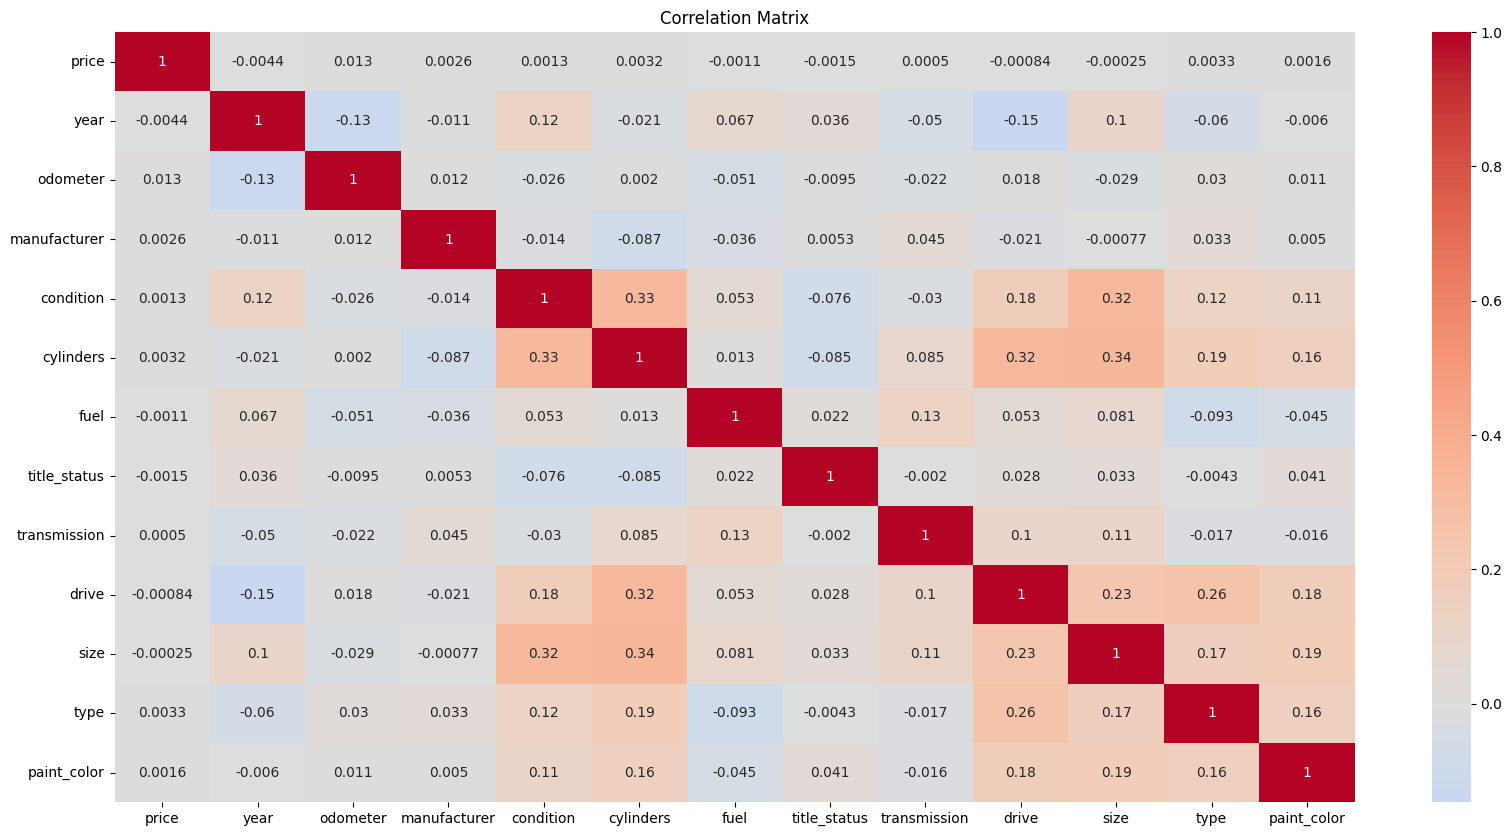

In [87]:
# Create a correlation matrix to visualize the correlation between the features and the target variable (price)
correlation_matrix = vehicle_cleansed_df.corr()

# Create the heatmap to visualize the correlation matrix
plt.figure(figsize=(20, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

Model Coefficients (Slopes): [-5.21029516e+03  1.04467466e+00  4.35101522e+03  7.73172359e+03
  3.04437635e+04  3.25010597e+04 -1.30605061e+04  3.07990656e+04
 -5.16104868e+04 -1.03638118e+04  1.16707578e+04  3.15789918e+03]
Model Intercept: 10116025.584312763
Mean Squared Error (MSE): 54690087066618.95
R-squared (R2) Score: -0.0017687224691596004


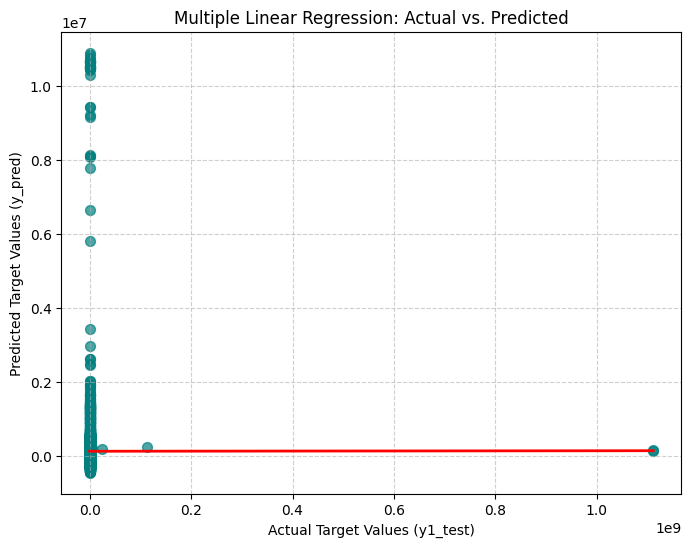

In [93]:
# Create Linear Regression Model from the data set to predict the price of a vehicle based on the features in the dataset

# X1 must be a 2D array (features), y1 is a 1D array (target)
X1 = vehicle_cleansed_df.drop('price', axis=1)
y1 = vehicle_cleansed_df['price']
# Split data into training set (80%) and testing set (20%)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size = 0.2, random_state = 42)
# Initialize the Linear Regression model
model = LinearRegression()
# Train the model using the training data
model.fit(X1_train, y1_train)
# Predict results on the test data
y_pred = model.predict(X1_test)
# Evaluate the model performance
print("Model Coefficients (Slopes):", model.coef_)
print("Model Intercept:", model.intercept_)
print("Mean Squared Error (MSE):", mean_squared_error(y1_test, y_pred))
print("R-squared (R2) Score:", r2_score(y1_test, y_pred))

# Plot Actual vs. Predicted values using Seaborn
plt.figure(figsize=(8, 6))

# sns.regplot draws the scatter plot and fits an ideal trendline for your predictions
sns.regplot(x=y1_test, y=y_pred, ci=None, color="teal", 
            scatter_kws={"s": 50, "alpha": 0.7}, 
            line_kws={"color": "red", "lw": 2})

plt.title('Multiple Linear Regression: Actual vs. Predicted')
plt.xlabel('Actual Target Values (y1_test)')
plt.ylabel('Predicted Target Values (y_pred)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.